## 07.CROSS VALIDATION

### Objective

The objective of this stage is to evaluate the consistency and reliability of the five machine learning models using cross-validation.
Cross-validation divides the training dataset into multiple subsets. Each subset is used once for validation, while the remaining subsets are used for training.
In this project, we use 5-Fold Stratified Cross-Validation to evaluate the models.

In [1]:
### Importing Required Libraries
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold, cross_val_score

from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier

In [7]:
# Load the dataset
df = pd.read_csv("../data/student-mat.csv", sep=";")

# Create target variable
df["Result"] = df["G3"].apply(lambda x: "Pass" if x >= 10 else "Fail")

# Separate features and target
X = df.drop(columns=["G1", "G2", "G3", "Result"])
y = df["Result"]

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (395, 34)


In [15]:
# Identify numerical features
numeric_features = X.select_dtypes(
    include=["int64", "float64"]
).columns

# Identify categorical features
categorical_features = X.select_dtypes(
    include=["object","str"]
).columns

# Split the dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (316, 30)
Testing data shape: (79, 30)


### 7.1 Data Preprocessing

Numerical features are standardized using StandardScaler.

Categorical features are converted into numerical form using OneHotEncoder.

Preprocessing is included inside the pipeline to prevent data leakage during cross-validation.

In [9]:
# Create preprocessing function
def create_preprocessor():

    return ColumnTransformer(
        transformers=[
            ("num", StandardScaler(), numeric_features),
            ("cat", OneHotEncoder(handle_unknown="ignore"),
             categorical_features)
        ]
    )

In [10]:
# Define the five models
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": SVC(
        kernel="rbf",
        random_state=42
    ),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "MLP": MLPClassifier(
        hidden_layer_sizes=(100,),
        max_iter=1000,
        random_state=42
    )
}

print("All five models defined successfully!")

All five models defined successfully!


### 7.2 Setting Up Cross-Validation

We use Stratified K-Fold Cross-Validation with five folds.

The training dataset is divided into five subsets. Each subset is used once for validation, while the remaining four subsets are used for training.

This helps evaluate the consistency of the models.

In [11]:
# Create 5-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

print("5-Fold Cross-Validation created successfully!")

5-Fold Cross-Validation created successfully!


In [12]:
# Store cross-validation results
cv_results = []

# Perform cross-validation for each model
for name, model in models.items():

    # Create pipeline
    pipeline = Pipeline(
        steps=[
            ("preprocessing", create_preprocessor()),
            ("model", model)
        ]
    )

    # Calculate cross-validation scores
    scores = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=-1
    )

    # Store results
    cv_results.append({
        "Model": name,
        "Fold 1": scores[0],
        "Fold 2": scores[1],
        "Fold 3": scores[2],
        "Fold 4": scores[3],
        "Fold 5": scores[4],
        "Mean F1-score": scores.mean(),
        "Standard Deviation": scores.std()
    })

    print(name, "completed!")

Decision Tree completed!
Random Forest completed!
SVM completed!
KNN completed!
MLP completed!


### 7.3 Comparing Cross-Validation Results

We create a comparison table showing the F1-score obtained in each fold, the mean F1-score and the standard deviation.

A higher mean F1-score indicates better average performance.

A lower standard deviation indicates more consistent performance across the folds.

In [13]:
# Create comparison DataFrame
cv_results_df = pd.DataFrame(cv_results)

# Sort models by mean F1-score
cv_results_df = cv_results_df.sort_values(
    by="Mean F1-score",
    ascending=False
)

# Display results
display(cv_results_df.round(3))

,Model,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5,Mean F1-score,Standard Deviation
0,Decision Tree,0.562,0.670,0.643,0.679,0.533,0.617,0.059
2,SVM,0.566,0.610,0.458,0.633,0.646,0.583,0.068
3,KNN,0.571,0.551,0.541,0.551,0.619,0.567,0.028
4,MLP,0.449,0.607,0.611,0.533,0.597,0.559,0.062
1,Random Forest,0.497,0.569,0.551,0.651,0.505,0.555,0.055


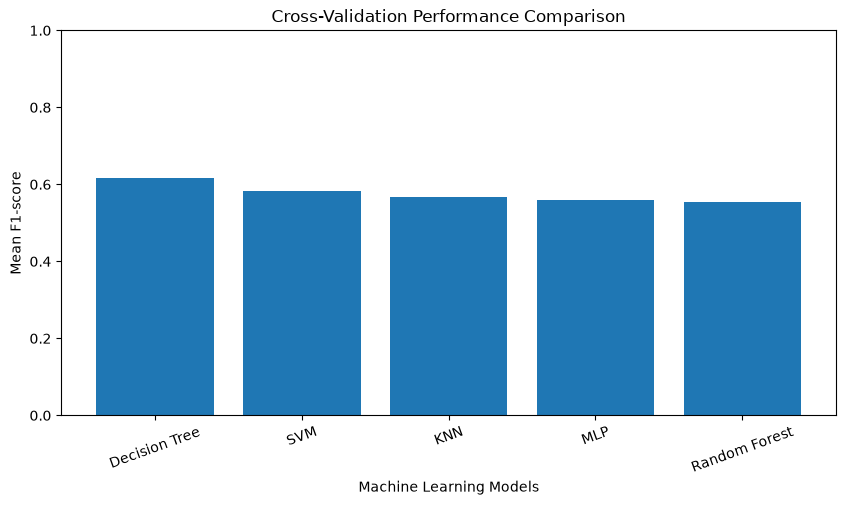

In [14]:
### Visualizing Cross-Validation Results

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.bar(
    cv_results_df["Model"],
    cv_results_df["Mean F1-score"]
)

plt.xlabel("Machine Learning Models")
plt.ylabel("Mean F1-score")
plt.title("Cross-Validation Performance Comparison")

plt.ylim(0, 1)
plt.xticks(rotation=20)

plt.show()

### Conclusion

5-Fold Stratified Cross-Validation was performed on all five machine learning models.

The mean F1-score was used to compare their average performance, while standard deviation was used to understand the consistency of the models.

The results help identify suitable models for further hyperparameter tuning.

In the next stage, hyperparameter tuning will be performed to improve model performance by selecting suitable parameter combinations.